# Prediksi Karyawan Resign (Employee Attrition)
**Fajar Sidiq Cahyanto — Proyek Machine Learning**

**Pertanyaan bisnis:** karyawan mana yang berisiko resign, dan faktor kerja apa yang paling mendorongnya, supaya HR bisa melakukan intervensi lebih awal (retensi, evaluasi beban kerja, jalur promosi)?

**Data:** IBM HR Analytics Employee Attrition — 1.470 karyawan, 35 kolom. Dataset ini **fiktif** buatan data scientist IBM, umum dipakai untuk studi kasus.

**Alur (CRISP-DM singkat):** pahami data → EDA → pilih fitur yang adil → bandingkan model dengan cross-validation → tentukan ambang keputusan → evaluasi sekali di data uji → jelaskan faktor pendorong → ekspor model untuk simulator web.

In [1]:
import json, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_predict
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (roc_auc_score, average_precision_score, roc_curve,
                             precision_recall_curve, confusion_matrix, precision_score, recall_score, fbeta_score)
warnings.filterwarnings('ignore')
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
RS = 42

df = pd.read_csv('data/ibm_hr_attrition.csv', encoding='utf-8-sig')
print(df.shape)
df.head()

(1470, 35)


,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2


## 1. Kualitas data

In [2]:
print('Missing value total :', df.isna().sum().sum())
print('Duplikat            :', df.duplicated().sum())
konstan = df.columns[df.nunique() <= 1].tolist()
print('Kolom konstan       :', konstan)
y = (df['Attrition'] == 'Yes').astype(int)
print(f"Attrition rate      : {y.mean():.1%}  ({y.sum()} dari {len(y)} karyawan)")

Missing value total : 0
Duplikat            : 0
Kolom konstan       : ['EmployeeCount', 'Over18', 'StandardHours']
Attrition rate      : 16.1%  (237 dari 1470 karyawan)


Data bersih: tidak ada missing value atau duplikat. Tiga kolom konstan (`EmployeeCount`, `Over18`, `StandardHours`) dan ID (`EmployeeNumber`) dibuang. Kelas **tidak seimbang** (16% resign), jadi akurasi bukan metrik yang tepat — 84% akurasi bisa didapat hanya dengan menebak "tidak resign" untuk semua orang. Fokus metrik: **ROC-AUC, PR-AUC, recall, dan precision**.

## 2. Exploratory Data Analysis

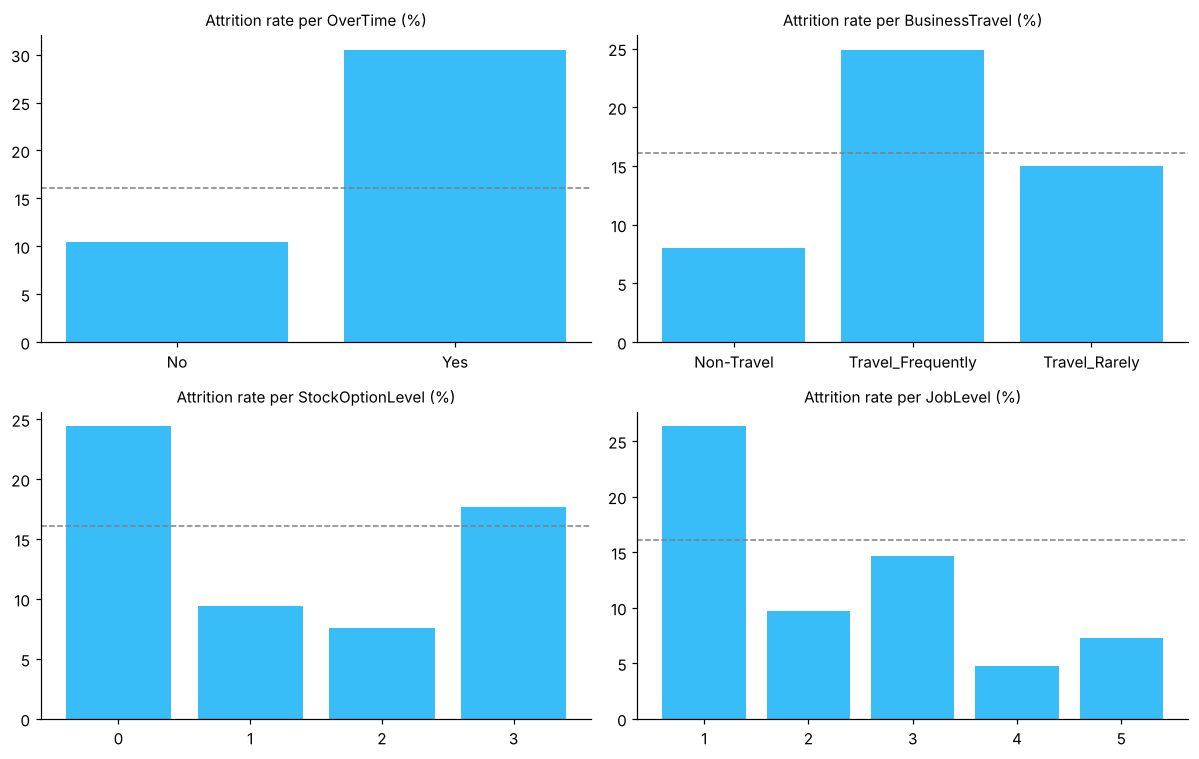

,attrition %
JobRole,
Sales Representative,39.8
Laboratory Technician,23.9
Human Resources,23.1
Sales Executive,17.5
Research Scientist,16.1
Manufacturing Director,6.9
Healthcare Representative,6.9
Manager,4.9
Research Director,2.5


In [3]:
def rate(col):
    return df.groupby(col)['Attrition'].apply(lambda s: (s == 'Yes').mean()).sort_values(ascending=False)

fig, ax = plt.subplots(2, 2, figsize=(11, 7))
for a, col in zip(ax.flat, ['OverTime', 'BusinessTravel', 'StockOptionLevel', 'JobLevel']):
    r = rate(col).sort_index()
    a.bar(r.index.astype(str), r.values * 100, color='#38bdf8')
    a.axhline(y.mean() * 100, ls='--', c='grey', lw=1)
    a.set_title(f'Attrition rate per {col} (%)', fontsize=10)
plt.tight_layout(); plt.show()
rate('JobRole').mul(100).round(1).to_frame('attrition %')

In [4]:
df['MasaKerjaTanpaPromosi'] = pd.cut(df.YearsSinceLastPromotion, [-1, 0, 2, 5, 20], labels=['0', '1-2', '3-5', '6+'])
df['BandGaji'] = pd.qcut(df.MonthlyIncome, 4, labels=['Q1 terendah', 'Q2', 'Q3', 'Q4 tertinggi'])
df['MasaKerja'] = pd.cut(df.YearsAtCompany, [-1, 1, 3, 5, 10, 40], labels=['0-1', '2-3', '4-5', '6-10', '11+'])
display(rate('BandGaji').sort_index().mul(100).round(1).to_frame('attrition %'))
display(rate('MasaKerja').sort_index().mul(100).round(1).to_frame('attrition %'))
df = df.drop(columns=['MasaKerjaTanpaPromosi', 'BandGaji', 'MasaKerja'])

,attrition %
BandGaji,
Q1 terendah,29.3
Q2,14.2
Q3,10.6
Q4 tertinggi,10.3


,attrition %
MasaKerja,
0-1,34.9
2-3,18.4
4-5,13.1
6-10,12.3
11+,8.1


**Temuan EDA:**
- Karyawan yang **lembur** resign ~3x lebih sering (30,5% vs 10,4%).
- **Sales Representative** (39,8%) dan **Laboratory Technician** (23,9%) adalah peran paling rawan.
- **Job level 1** dan karyawan **tanpa opsi saham** (level 0) jauh di atas rata-rata.
- Risiko tertinggi ada di **kuartil gaji terendah** dan di **tahun pertama** bekerja.

## 3. Pemilihan fitur yang adil
Model untuk keputusan SDM tidak boleh mendiskriminasi. Karena itu **gender, status pernikahan, dan usia tidak dipakai** sebagai fitur, walaupun secara statistik ikut berkorelasi. Saya hanya memakai faktor **terkait pekerjaan** yang bisa ditindaklanjuti HR. Kolom `DailyRate`, `HourlyRate`, `MonthlyRate` juga dibuang karena tidak konsisten dengan `MonthlyIncome` (noise).

Rekayasa fitur: `MonthlyIncome` ditransformasi log (sebaran miring kanan); `JobLevel` dan `StockOptionLevel` diperlakukan sebagai kategori karena hubungannya dengan attrition tidak linear (lihat grafik di atas).

In [5]:
NUM = ['DistanceFromHome', 'EnvironmentSatisfaction', 'JobInvolvement', 'JobSatisfaction',
       'NumCompaniesWorked', 'TotalWorkingYears', 'WorkLifeBalance', 'YearsAtCompany',
       'YearsSinceLastPromotion', 'YearsWithCurrManager', 'RelationshipSatisfaction', 'TrainingTimesLastYear']
LOG = ['MonthlyIncome']
CAT = ['OverTime', 'BusinessTravel', 'JobRole', 'StockOptionLevel', 'JobLevel']
FEATURES = NUM + LOG + CAT

X = df[FEATURES]
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, stratify=y, random_state=RS)
print('Train:', X_tr.shape, f'resign {y_tr.mean():.1%}', '| Test:', X_te.shape, f'resign {y_te.mean():.1%}')

def preprocessor():
    return ColumnTransformer([
        ('num', StandardScaler(), NUM),
        ('log', Pipeline([('log', FunctionTransformer(np.log1p, feature_names_out='one-to-one')), ('sc', StandardScaler())]), LOG),
        ('cat', OneHotEncoder(handle_unknown='ignore', drop='first'), CAT)])

Train: (1176, 18) resign 16.2% | Test: (294, 18) resign 16.0%


## 4. Perbandingan model (5-fold cross-validation, hanya data train)
Data uji **tidak disentuh** sampai model dan ambang dipilih.

In [6]:
cv = StratifiedKFold(5, shuffle=True, random_state=RS)
kandidat = {
    'Logistic Regression': LogisticRegression(max_iter=3000, C=0.3),
    'Random Forest': RandomForestClassifier(400, min_samples_leaf=3, class_weight='balanced_subsample', random_state=RS, n_jobs=-1),
    'Gradient Boosting': HistGradientBoostingClassifier(max_depth=3, learning_rate=0.05, max_iter=300, class_weight='balanced', random_state=RS),
}
hasil, oof_all = [], {}
for nama, m in kandidat.items():
    pipe = Pipeline([('prep', preprocessor()), ('model', m)])
    oof = cross_val_predict(pipe, X_tr, y_tr, cv=cv, method='predict_proba')[:, 1]
    oof_all[nama] = oof
    hasil.append({'Model': nama, 'ROC-AUC': roc_auc_score(y_tr, oof), 'PR-AUC': average_precision_score(y_tr, oof)})
cv_table = pd.DataFrame(hasil).sort_values('ROC-AUC', ascending=False).round(3)
cv_table

,Model,ROC-AUC,PR-AUC
0,Logistic Regression,0.855,0.672
2,Gradient Boosting,0.807,0.582
1,Random Forest,0.797,0.529


**Logistic Regression** unggul di kedua metrik, sekaligus paling mudah dijelaskan (tiap faktor punya koefisien yang bisa dibaca HR). Model ini dipilih. Model dilatih tanpa `class_weight` agar outputnya tetap berupa **peluang yang realistis** (rata-rata ~16%), lalu ketidakseimbangan kelas ditangani lewat **ambang keputusan**.

## 5. Menentukan ambang keputusan
Bagi HR, melewatkan karyawan yang benar-benar akan resign lebih mahal daripada mengajak ngobrol karyawan yang ternyata aman. Karena itu ambang dipilih dengan memaksimalkan **F2-score** (recall dibobot 2x precision) pada prediksi out-of-fold.

Ambang terpilih: 0.18
CV recall 77.9% | CV precision 42.5%


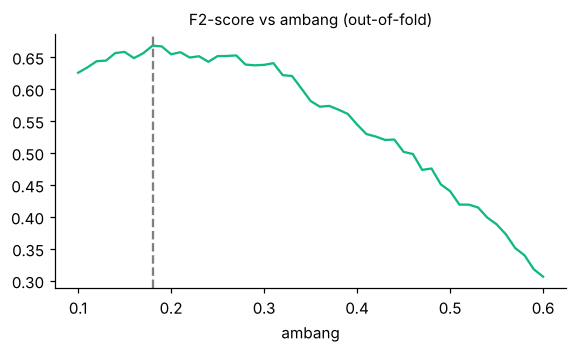

In [7]:
oof = oof_all['Logistic Regression']
grid = np.round(np.arange(0.10, 0.61, 0.01), 2)
f2 = [fbeta_score(y_tr, oof >= t, beta=2) for t in grid]
THRESHOLD = float(grid[int(np.argmax(f2))])
print(f'Ambang terpilih: {THRESHOLD:.2f}')
print(f'CV recall {recall_score(y_tr, oof >= THRESHOLD):.1%} | CV precision {precision_score(y_tr, oof >= THRESHOLD):.1%}')
plt.figure(figsize=(6, 3)); plt.plot(grid, f2, c='#10b981'); plt.axvline(THRESHOLD, ls='--', c='grey')
plt.title('F2-score vs ambang (out-of-fold)', fontsize=10); plt.xlabel('ambang'); plt.show()

## 6. Evaluasi akhir di data uji (294 karyawan, dipakai sekali)

In [8]:
final = Pipeline([('prep', preprocessor()), ('model', LogisticRegression(max_iter=3000, C=0.3))]).fit(X_tr, y_tr)
p_te = final.predict_proba(X_te)[:, 1]
pred = (p_te >= THRESHOLD).astype(int)
tn, fp, fn, tp = confusion_matrix(y_te, pred).ravel()
test_metrics = {
    'roc_auc': roc_auc_score(y_te, p_te), 'pr_auc': average_precision_score(y_te, p_te),
    'recall': recall_score(y_te, pred), 'precision': precision_score(y_te, pred),
    'tp': int(tp), 'fp': int(fp), 'fn': int(fn), 'tn': int(tn), 'base_rate': float(y_te.mean()),
}
print(f"ROC-AUC {test_metrics['roc_auc']:.3f} | PR-AUC {test_metrics['pr_auc']:.3f} (baseline acak = {y_te.mean():.3f})")
print(f"Recall {test_metrics['recall']:.1%} | Precision {test_metrics['precision']:.1%}")
pd.DataFrame([[tn, fp], [fn, tp]], index=['Aktual: bertahan', 'Aktual: resign'], columns=['Prediksi: aman', 'Prediksi: berisiko'])

ROC-AUC 0.836 | PR-AUC 0.665 (baseline acak = 0.160)
Recall 74.5% | Precision 38.5%


,Prediksi: aman,Prediksi: berisiko
Aktual: bertahan,191,56
Aktual: resign,12,35


Fokus ke 10% karyawan berisiko tertinggi -> menangkap 51% dari yang resign
Fokus ke 20% karyawan berisiko tertinggi -> menangkap 68% dari yang resign
Fokus ke 30% karyawan berisiko tertinggi -> menangkap 74% dari yang resign
Fokus ke 40% karyawan berisiko tertinggi -> menangkap 79% dari yang resign
Fokus ke 50% karyawan berisiko tertinggi -> menangkap 85% dari yang resign


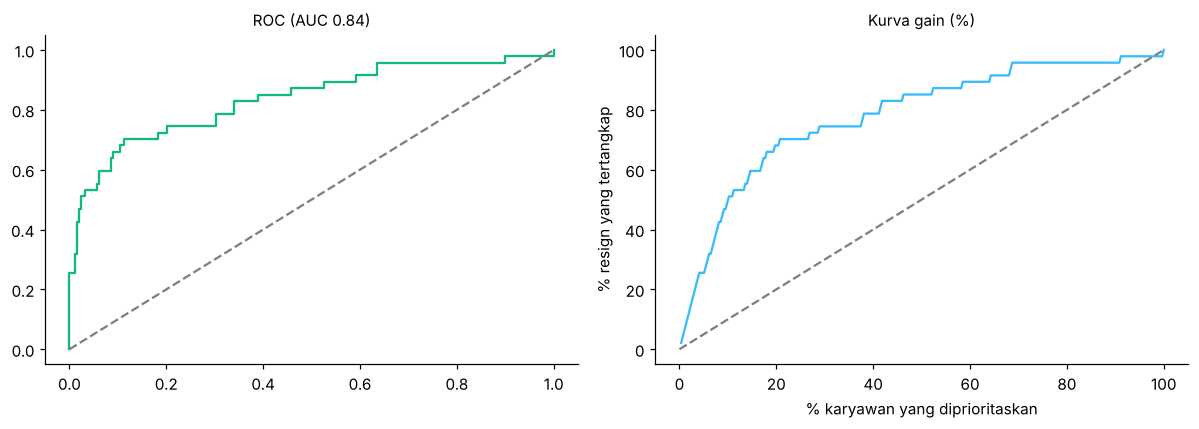

In [9]:
# Kurva gain: jika HR fokus ke X% karyawan dengan skor tertinggi, berapa % yang resign tertangkap?
order = np.argsort(-p_te)
cum = np.cumsum(y_te.values[order]) / y_te.sum()
pct = np.arange(1, len(order) + 1) / len(order)
gain = {int(k): float(cum[int(np.ceil(k / 100 * len(order))) - 1]) for k in [10, 20, 30, 40, 50]}
for k, v in gain.items():
    print(f'Fokus ke {k:>2}% karyawan berisiko tertinggi -> menangkap {v:.0%} dari yang resign')
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
fpr, tpr, _ = roc_curve(y_te, p_te)
ax[0].plot(fpr, tpr, c='#10b981'); ax[0].plot([0, 1], [0, 1], ls='--', c='grey'); ax[0].set_title(f"ROC (AUC {test_metrics['roc_auc']:.2f})", fontsize=10)
ax[1].plot(pct * 100, cum * 100, c='#38bdf8'); ax[1].plot([0, 100], [0, 100], ls='--', c='grey'); ax[1].set_title('Kurva gain (%)', fontsize=10)
ax[1].set_xlabel('% karyawan yang diprioritaskan'); ax[1].set_ylabel('% resign yang tertangkap')
plt.tight_layout(); plt.show()

## 7. Faktor pendorong resign
Koefisien diubah menjadi **odds ratio**. Untuk fitur numerik: efek kenaikan 1 standar deviasi. Untuk kategori: dibanding kategori acuan.

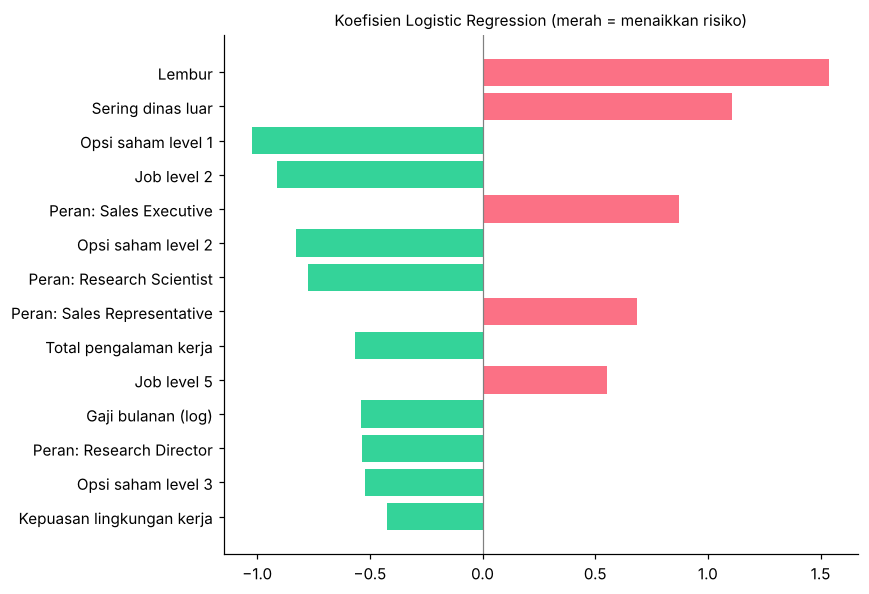

,faktor,koef,odds_ratio
0,Lembur,1.54,4.66
1,Sering dinas luar,1.11,3.02
2,Opsi saham level 1,-1.02,0.36
3,Job level 2,-0.91,0.40
4,Peran: Sales Executive,0.87,2.39
5,Opsi saham level 2,-0.83,0.44
6,Peran: Research Scientist,-0.77,0.46
7,Peran: Sales Representative,0.68,1.98
8,Total pengalaman kerja,-0.57,0.57
9,Job level 5,0.55,1.74


In [10]:
prep, lr = final.named_steps['prep'], final.named_steps['model']
names = prep.get_feature_names_out()
coef = pd.Series(lr.coef_[0], index=names)
LABEL = {
    'OverTime_Yes': 'Lembur', 'BusinessTravel_Travel_Frequently': 'Sering dinas luar',
    'BusinessTravel_Travel_Rarely': 'Kadang dinas luar', 'StockOptionLevel_0': 'Tanpa opsi saham',
    'JobLevel_1': 'Job level 1', 'MonthlyIncome': 'Gaji bulanan (log)',
    'YearsSinceLastPromotion': 'Lama sejak promosi terakhir', 'NumCompaniesWorked': 'Jumlah perusahaan sebelumnya',
    'EnvironmentSatisfaction': 'Kepuasan lingkungan kerja', 'JobSatisfaction': 'Kepuasan kerja',
    'JobInvolvement': 'Keterlibatan kerja', 'WorkLifeBalance': 'Work-life balance',
    'TotalWorkingYears': 'Total pengalaman kerja', 'YearsWithCurrManager': 'Lama dengan atasan sekarang',
    'DistanceFromHome': 'Jarak rumah', 'YearsAtCompany': 'Masa kerja di perusahaan',
    'RelationshipSatisfaction': 'Kepuasan relasi kerja', 'TrainingTimesLastYear': 'Jumlah pelatihan tahun lalu',
}
def label(n):
    raw = n.split('__', 1)[1]
    if raw.startswith('JobRole_'): return 'Peran: ' + raw[8:]
    if raw.startswith('StockOptionLevel_') and raw not in LABEL: return 'Opsi saham level ' + raw[-1]
    if raw.startswith('JobLevel_') and raw not in LABEL: return 'Job level ' + raw[-1]
    return LABEL.get(raw, raw)
drivers = pd.DataFrame({'faktor': [label(n) for n in names], 'koef': coef.values, 'odds_ratio': np.exp(coef.values)})
drivers = drivers.reindex(drivers.koef.abs().sort_values(ascending=False).index).reset_index(drop=True)
top = drivers.head(14).iloc[::-1]
plt.figure(figsize=(8, 5.5))
plt.barh(top.faktor, top.koef, color=['#fb7185' if k > 0 else '#34d399' for k in top.koef])
plt.axvline(0, c='grey', lw=.8); plt.title('Koefisien Logistic Regression (merah = menaikkan risiko)', fontsize=10)
plt.tight_layout(); plt.show()
drivers.head(14).round(2)

**Interpretasi untuk HR:**
- **Lembur** adalah pendorong terbesar yang bisa langsung dikendalikan → evaluasi beban kerja & rotasi.
- **Dinas luar yang sering**, **job level 1**, dan **tanpa opsi saham** menaikkan risiko → program retensi untuk level junior (opsi saham/insentif jangka panjang).
- **Lama tanpa promosi** dan **seringnya pindah kerja** di masa lalu menaikkan risiko; **kepuasan lingkungan & pekerjaan, work-life balance**, dan **lama dengan atasan yang sama** menurunkannya → pentingnya jalur karier dan kualitas manajer.

**Catatan etis:** model ini alat bantu **prioritas percakapan retensi**, bukan dasar keputusan disiplin atau PHK. Skor individu harus selalu didiskusikan bersama atasan langsung.

## 8. Ekspor model untuk simulator web
Preprocessing + koefisien diekspor ke JSON sehingga skor bisa dihitung langsung di browser (tanpa server).

In [11]:
sc_num = prep.named_transformers_['num']; sc_log = prep.named_transformers_['log'].named_steps['sc']
ohe = prep.named_transformers_['cat']
model_json = {
    'intercept': float(lr.intercept_[0]), 'threshold': THRESHOLD, 'base_rate': float(y.mean()),
    'num': [{'name': n, 'mean': float(m), 'scale': float(s), 'coef': float(coef['num__' + n])}
            for n, m, s in zip(NUM, sc_num.mean_, sc_num.scale_)],
    'log': [{'name': n, 'mean': float(m), 'scale': float(s), 'coef': float(coef['log__' + n])}
            for n, m, s in zip(LOG, sc_log.mean_, sc_log.scale_)],
    'cat': [{'name': n, 'base': str(cats[0]),
             'coef': {str(c): float(coef[f'cat__{n}_{c}']) for c in cats[1:]},
             'mean': {str(c): float((X_tr[n].astype(str) == str(c)).mean()) for c in cats[1:]}}
            for n, cats in zip(CAT, ohe.categories_)],
}
# Rangkuman untuk halaman showcase
def rate_list(col):
    g = df.groupby(col)['Attrition'].agg(n='size', r=lambda s: (s == 'Yes').mean()).reset_index()
    return [{'k': str(k), 'n': int(n), 'r': float(r)} for k, n, r in g.itertuples(index=False)]
fpr, tpr, _ = roc_curve(y_te, p_te)
idx = np.unique(np.linspace(0, len(fpr) - 1, 60).astype(int))
report = {
    'n': len(df), 'n_resign': int(y.sum()), 'n_train': len(X_tr), 'n_test': len(X_te),
    'cv': cv_table.to_dict('records'), 'test': test_metrics, 'gain': gain,
    'gain_curve': [[round(float(a) * 100, 1), round(float(b) * 100, 1)] for a, b in zip(pct[::3], cum[::3])],
    'roc': [[round(float(fpr[i]), 3), round(float(tpr[i]), 3)] for i in idx],
    'drivers': drivers.head(14).round(3).to_dict('records'),
    'eda': {c: rate_list(c) for c in ['OverTime', 'BusinessTravel', 'JobRole', 'StockOptionLevel', 'JobLevel', 'WorkLifeBalance', 'EnvironmentSatisfaction']},
}
json.dump({'model': model_json, 'report': report}, open('attrition_model.json', 'w'), ensure_ascii=False, indent=1)

# Uji: skor dari JSON harus sama dengan sklearn
def score(row):
    z = model_json['intercept']
    for f in model_json['num']: z += f['coef'] * (row[f['name']] - f['mean']) / f['scale']
    for f in model_json['log']: z += f['coef'] * (np.log1p(row[f['name']]) - f['mean']) / f['scale']
    for f in model_json['cat']: z += f['coef'].get(str(row[f['name']]), 0.0)
    return 1 / (1 + np.exp(-z))
cek = np.array([score(r) for _, r in X_te.iterrows()])
print('Selisih maks JSON vs sklearn:', float(np.abs(cek - p_te).max()))

Selisih maks JSON vs sklearn: 2.7755575615628914e-16


## 9. Kesimpulan
- Model Logistic Regression dengan 18 faktor kerja (tanpa atribut demografis sensitif) mencapai **ROC-AUC ~0,84** di data uji.
- Dengan memprioritaskan sebagian kecil karyawan berskor tertinggi, HR bisa menangkap porsi besar karyawan yang akan resign (lihat kurva gain) — jauh lebih efisien daripada program retensi untuk semua orang.
- Faktor yang paling bisa ditindaklanjuti: **lembur, frekuensi dinas luar, insentif jangka panjang untuk level junior, dan jalur promosi**.

**Batasan:** dataset fiktif dan relatif kecil (1.470 baris, 237 resign); hasil perlu divalidasi ulang dengan data perusahaan sungguhan, dan model perlu dipantau berkala (drift).